
## 1.1 Parametri DH e matrice di trasformazione omogenea

I parametri di Denavit-Hartenberg (DH) descrivono la geometria di un robot
a catena cinematica aperta. Per ogni giunto i si definiscono quattro parametri:
- `a[i]`: lunghezza del link (distanza tra gli assi z_i-1 e z_i)
- `d[i]`: offset lungo l'asse z (distanza tra i link)
- `alpha[i]`: angolo di torsione del link (rotazione intorno all'asse x)
- `q[i]`: variabile di giunto (angolo di rotazione intorno all'asse z)

La funzione `trasf_DH()` costruisce la matrice di trasformazione omogenea 4x4
che esprime la posa (posizione + orientamento) del frame `i` rispetto al frame `i-1`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


#definizione parametri di DH
a = np.array([0.09, 0.005, 0.035, 0.02])
d = np.array([0.0, 0.0, 0.05, 0.0])
alpha = np.array([np.pi/2, -np.pi/2 , np.pi/2, 0.0])
q = np.array([0.0, 0.0, 0.0, 0.0])

#definizione matrice di trasformazione di Denavit-Hartenberg
def trasf_DH(d, a, alpha, theta):
  T = np.array([
          [np.cos(theta), -np.sin(theta)*np.cos(alpha), np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
          [np.sin(theta), np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
          [0.0,           np.sin(alpha),               np.cos(alpha),               d],
          [0.0,           0.0,                         0.0,                         1.0]
      ])
  return T


In [3]:
#definizione delle matrici di trasformazione

T0 = np.eye(4) 
T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
T34 = trasf_DH(d[3], a[3], alpha[3], q[3])                
T02 = np.matmul(T01,T12)
T03 = np.matmul(T02,T23)
T04 = np.matmul(T03,T34)

print(T04[:3, 3])


[0.15 0.   0.05]


## 1.2 Visualizzazione 3D della catena cinematica

Questa cella estrae le posizioni dei frame di ogni giunto dalle matrici di
trasformazione omogenea e le visualizza in uno spazio 3D. Viene inoltre
gestito il caso particolare del giunto 3, il cui centro non coincide
con l'origine del frame T03 ma è traslato lungo l'asse z locale di T02
di un offset pari a `d[2]`.

La funzione `terne()` disegna i tre assi (x, y, z) di ogni frame come
frecce colorate, permettendo di visualizzare sia la posizione che
l'orientamento di ciascun sistema di riferimento.

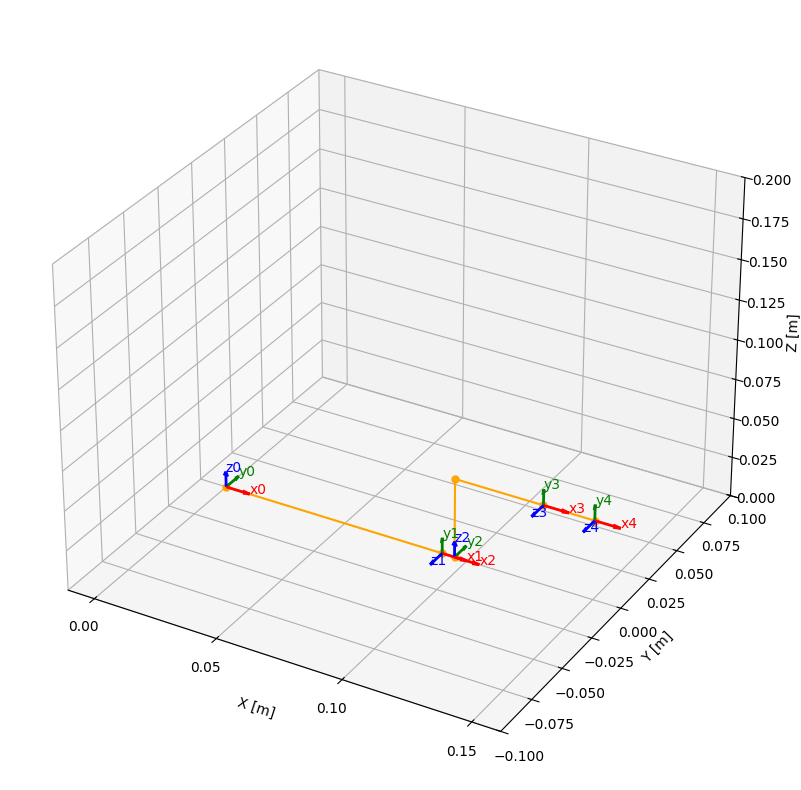

In [8]:
o0 = np.array([0, 0, 0])
o1 = T01[:3,3]
o2 = T02[:3,3]
z_locale_T02 = T02[:3, 2]  # asse z del sistema di riferimento di T02
pL = o2 + d[2] * z_locale_T02
o3 = T03[:3,3]
o4 = T04[:3,3]


x = [o0[0], o1[0], o2[0], pL[0], o3[0], o4[0]]
y = [o0[1], o1[1], o2[1], pL[1], o3[1], o4[1]]
z = [o0[2], o1[2], o2[2], pL[2], o3[2], o4[2]]


fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(x, y, z, marker='o', markersize=5, color='orange', label='Posizioni dei giunti')
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_zlabel('Z [m]')

def terne(ax, T, l, name=''):
    origin = T[:3, 3]
    x_asse = T[:3, 0] * l
    y_asse = T[:3, 1] * l
    z_asse = T[:3, 2] * l

    ax.quiver(*origin, *x_asse, color='red', linewidth=2)  
    ax.quiver(*origin, *y_asse, color='green', linewidth=2)  
    ax.quiver(*origin, *z_asse, color='blue', linewidth=2)  

    ax.text(*(origin + x_asse), f'x{name}', color='red', fontsize=10)
    ax.text(*(origin + y_asse), f'y{name}', color='green', fontsize=10)
    ax.text(*(origin + z_asse), f'z{name}', color='blue', fontsize=10)

terne(ax, np.eye(4), l=0.01, name='0')  # ← 1.5cm → 0.01m
terne(ax, T01,       l=0.01, name='1')
terne(ax, T02,       l=0.01, name='2')
terne(ax, T03,       l=0.01, name='3')
terne(ax, T04,       l=0.01, name='4')

ax.xaxis.set_major_locator(MultipleLocator(0.05))  # ← 5cm → 0.05
ax.set_ylim(-0.1, 0.1) 
ax.set_zlim(0, 0.2) 
plt.tight_layout()
plt.show()


## 1.3 Visualizzazione 2D della catena cinematica nel piano XZ

Quando la configurazione del robot è planare o si vuole analizzare il
comportamento nel piano di lavoro principale, la vista 3D può risultare
difficile da leggere. Questa cella proietta la catena cinematica sul
piano XZ, ottenendo una rappresentazione 2D più chiara.

La funzione `terne_2D_xz()` è analoga a `terne()` vista in precedenza,
ma usa `ax.quiver()` in versione 2D: anziché passare le tre componenti
(x, y, z) di ogni asse, si estraggono solo le componenti **x** e **z**,
ignorando la profondità y. I parametri `scale`, `scale_units` e `angles`
garantiscono che le frecce siano disegnate in scala corretta con le unità
degli assi del grafico.


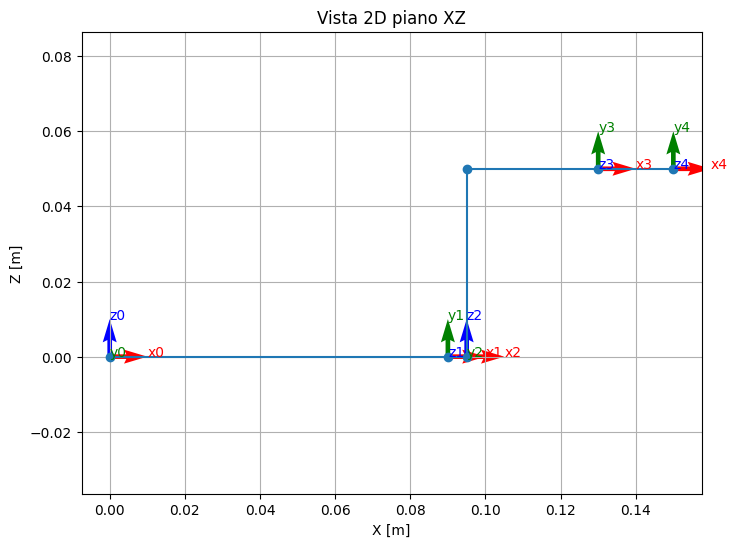

In [10]:
def terne_2D_xz(ax, T, l, name=''):
    origin = T[0:3, 3]

    x_asse = T[0:3, 0] * l
    y_asse = T[0:3, 1] * l
    z_asse = T[0:3, 2] * l

    ax.quiver(origin[0], origin[2], x_asse[0], x_asse[2], color='red', scale=1, scale_units='xy', angles='xy')
    ax.quiver(origin[0], origin[2], y_asse[0], y_asse[2], color='green', scale=1, scale_units='xy', angles='xy')
    ax.quiver(origin[0], origin[2], z_asse[0], z_asse[2], color='blue', scale=1, scale_units='xy', angles='xy')
    ax.text(origin[0] + x_asse[0], origin[2] + x_asse[2], 'x' + name, color='red')
    ax.text(origin[0] + y_asse[0], origin[2] + y_asse[2], 'y' + name, color='green')
    ax.text(origin[0] + z_asse[0], origin[2] + z_asse[2], 'z' + name, color='blue')

fig2 = plt.figure(figsize=(8, 6))
ax2 = fig2.add_subplot(111)

ax2.plot(x, z, marker='o')

terne_2D_xz(ax2, np.eye(4), 0.01, '0')  # ← 1cm → 0.01m
terne_2D_xz(ax2, T01, 0.01, '1')
terne_2D_xz(ax2, T02, 0.01, '2')
terne_2D_xz(ax2, T03, 0.01, '3')
terne_2D_xz(ax2, T04, 0.01, '4')

ax2.set_xlabel('X [m]')   # ← cm → m
ax2.set_ylabel('Z [m]')   # ← cm → m
ax2.set_title('Vista 2D piano XZ')
ax2.grid(True)
ax2.axis('equal')

plt.show()

## 1.4 Spazio di lavoro e visualizzazione della configurazione iniziale

Lo spazio di lavoro di un robot è l'insieme di tutte le posizioni
raggiungibili dall'end-effector al variare degli angoli di giunto entro
i loro limiti fisici. Per calcolarlo si esegue la **cinematica diretta**
su una griglia discreta di combinazioni angolari: per ogni combinazione
`(q1, q2, q3, q4)` si calcola la matrice `T04` e si estrae la posizione
dell'end-effector dalla colonna di traslazione.

I punti ottenuti vengono salvati su file e visualizzati in 3D insieme a:
- la **catena cinematica** nella configurazione iniziale `q = [0, 0, 0, 0]`
- i **punti della traiettoria** pianificata `pi`, `p1`, `p2`, utili per
  verificare che siano all'interno dello spazio di lavoro

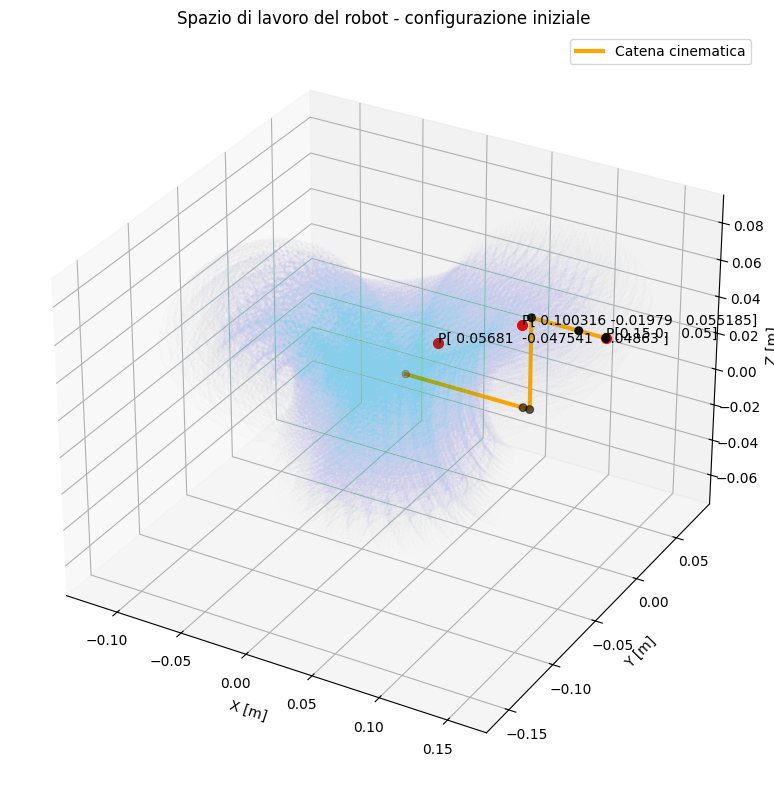

In [ ]:
# PLOT DELLO SPAZIO DI LAVORO
q1_range = np.radians(np.linspace(-129, 25, 15)) # 15 campioni
q2_range = np.radians(np.linspace(-10, 165, 30)) # 30 campioni  
q3_range = np.radians(np.linspace(-86, 11, 40)) # 40 campioni
q4_range = np.radians(np.linspace(0, 360, 40)) # 40 campioni

pi = np.array([0.15, 0.0  , 0.05])
p1 = np.array([0.100316, -0.019790, 0.055185])
p2 = np.array([0.056810, -0.047541, 0.048630])
punti_traiettoria = np.array([pi, p1, p2])

points = []

for q1 in q1_range: 
    for q2 in q2_range:
        for q3 in q3_range:
            for q4 in q4_range: 
                q = [q1, q2, q3, q4] # 15 * 30 * 40 * 40 = 720.000 combinazioni

                T0 = np.eye(4)
                T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
                T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
                T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
                T34 = trasf_DH(d[3], a[3], alpha[3], q[3])
                T02 = np.matmul(T01,T12)
                T03 = np.matmul(T02,T23)
                T04 = np.matmul(T03,T34)

                pos = T04[:3, 3]
                points.append(pos)

points = np.array(points)
np.savetxt("punti_spazio_lavoro.txt", points, fmt="%.4f", header="x y z", comments='') 

# Visualizzazione dello spazio di lavoro
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot dei punti dello spazio di lavoro
ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=0.00005, c='skyblue' , alpha=0.6) 

# Plot dei punti della traiettoria
for i in punti_traiettoria:
    ax.scatter(i[0], i[1], i[2], c='red', s= 50)
    ax.text(i[0], i[1], i[2], f"P{i}", color='black', zorder=10)

# Cinematica diretta nella configurazione iniziale
q_init = [0.0, 0.0, 0.0, 0.0]
T01 = trasf_DH(d[0], a[0], alpha[0], q_init[0])
T12 = trasf_DH(d[1], a[1], alpha[1], q_init[1])
T23 = trasf_DH(d[2], a[2], alpha[2], q_init[2])
T34 = trasf_DH(d[3], a[3], alpha[3], q_init[3])
T02 = np.matmul(T01, T12)
T03 = np.matmul(T02, T23)
T04 = np.matmul(T03, T34)

o0 = np.array([0, 0, 0])
o1 = T01[:3, 3]
o2 = T02[:3, 3]
pL = o2 + d[2] * T02[:3, 2]
o3 = T03[:3, 3]
o4 = T04[:3,3]


x = [o0[0], o1[0], o2[0], pL[0], o3[0], o4[0]]
y = [o0[1], o1[1], o2[1], pL[1], o3[1], o4[1]]
z = [o0[2], o1[2], o2[2], pL[2], o3[2], o4[2]]

# Catena cinematica
ax.plot(x, y, z, lw=3, color='orange', label='Catena cinematica')
ax.scatter(x, y, z, c='black', s=30, zorder=5)

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_zlabel('Z [m]')
ax.set_title('Spazio di lavoro del robot - configurazione iniziale')
ax.legend()

plt.tight_layout()
plt.show()